=== BẮT ĐẦU GIẢI ĐẤU ROUND-ROBIN (6 Agents | 15 cặp đấu x 10 ván/cặp) ===
  [Match] RandomAgent    vs HeuristicAgent | Thắng-Thua-Hòa: 0-10-0 | WinRate A:   0.0% | TB nước:  9.5
  [Match] RandomAgent    vs MinimaxAgent   | Thắng-Thua-Hòa: 0-10-0 | WinRate A:   0.0% | TB nước: 10.1
  [Match] RandomAgent    vs PureMCTS-400   | Thắng-Thua-Hòa: 0-10-0 | WinRate A:   0.0% | TB nước: 15.5
  [Match] RandomAgent    vs AlphaZero-Iter15 | Thắng-Thua-Hòa: 0-10-0 | WinRate A:   0.0% | TB nước: 21.1
  [Match] RandomAgent    vs AlphaZero-Iter25 | Thắng-Thua-Hòa: 0-10-0 | WinRate A:   0.0% | TB nước: 25.3
  [Match] HeuristicAgent vs MinimaxAgent   | Thắng-Thua-Hòa: 0-0-10 | WinRate A:   0.0% | TB nước: 121.0
  [Match] HeuristicAgent vs PureMCTS-400   | Thắng-Thua-Hòa: 10-0-0 | WinRate A: 100.0% | TB nước:  9.5
  [Match] HeuristicAgent vs AlphaZero-Iter15 | Thắng-Thua-Hòa: 10-0-0 | WinRate A: 100.0% | TB nước: 11.5
  [Match] HeuristicAgent vs AlphaZero-Iter25 | Thắng-Thua-Hòa: 10-0-0 | WinRate A: 100.

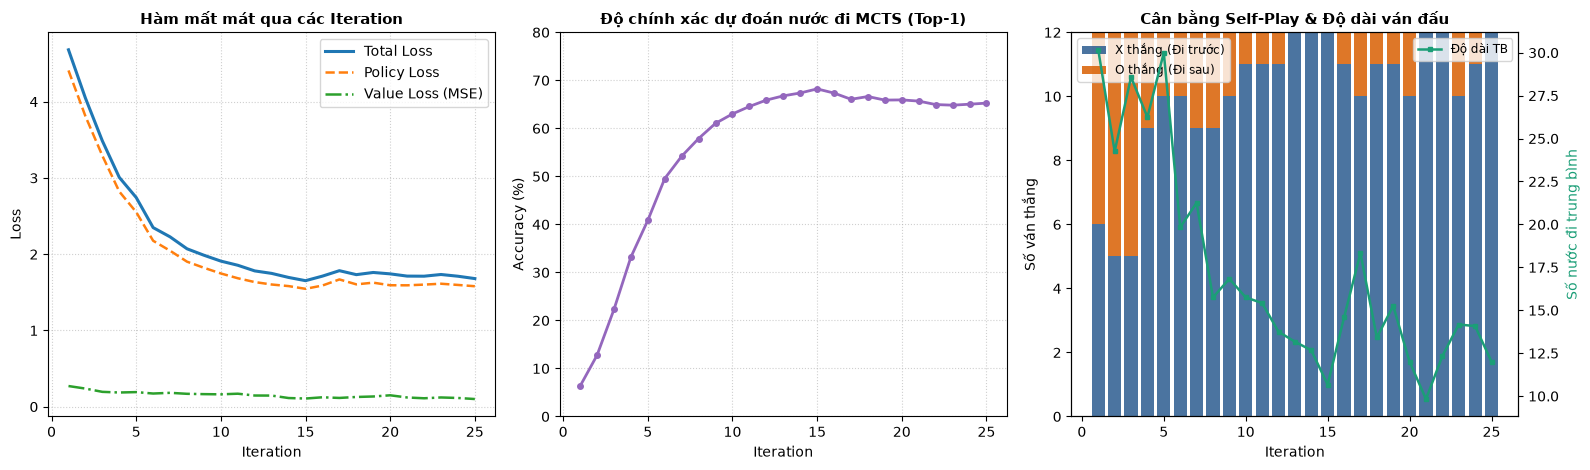

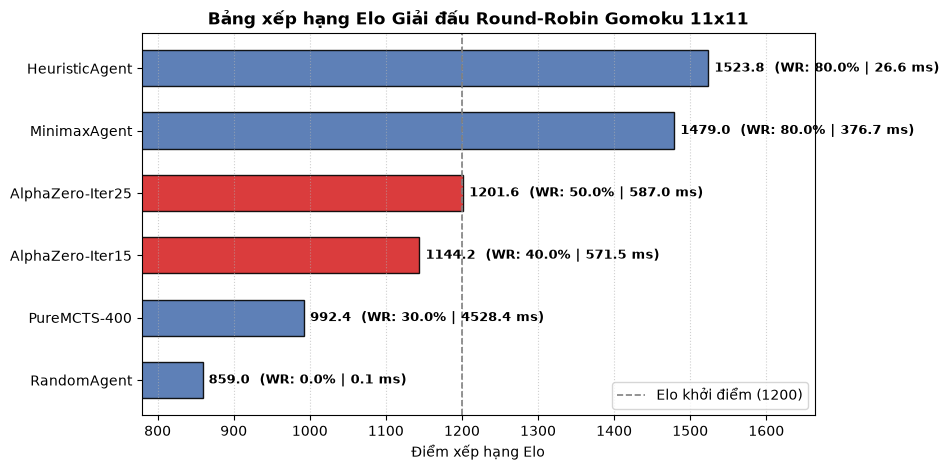

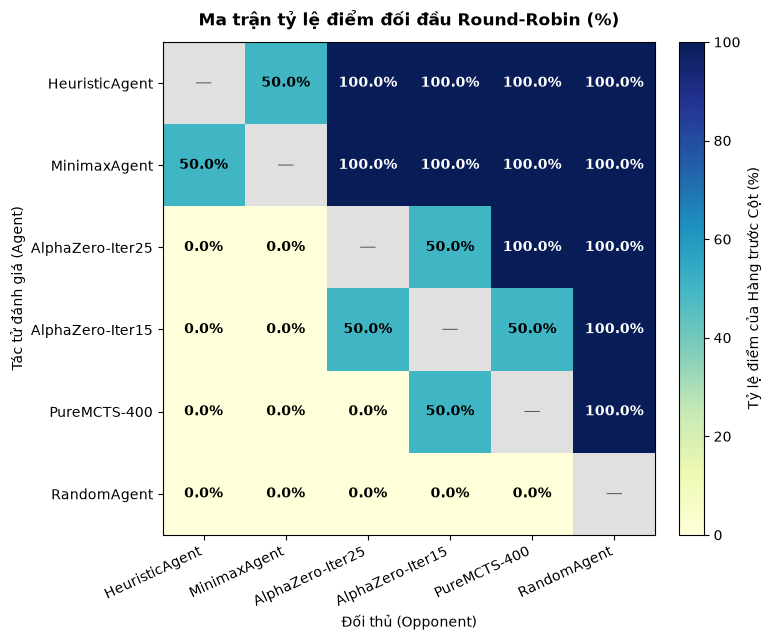

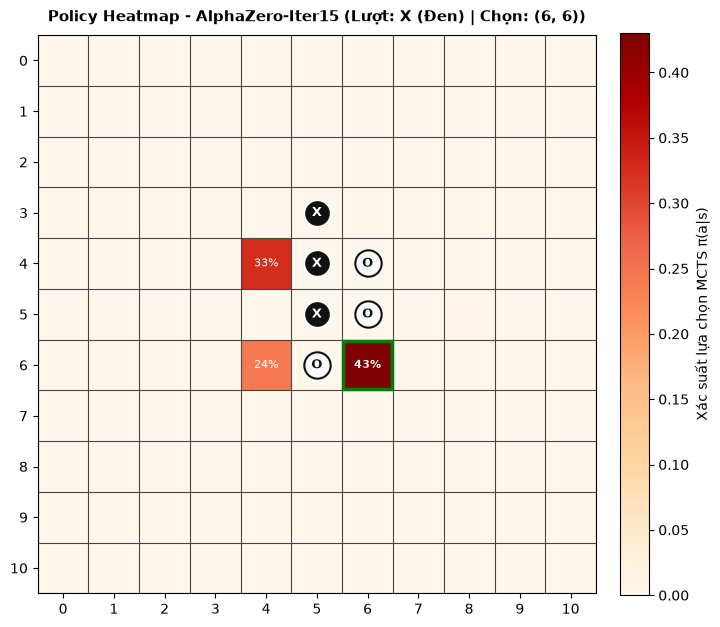

WindowsPath('D:/DSCKTTNTNC/TTNTNC-Nhom10-main/TTNTNC-Nhom10-main/gokumo_11x11_ai_research/logs/fig4_policy_heatmap.png')

In [3]:
import os
import sys
from pathlib import Path

# Đảm bảo trỏ về thư mục gốc dự án
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from agents.random_agent import RandomAgent
from agents.heuristic_agent import HeuristicAgent
from agents.minimax_agent import MinimaxAgent
from agents.pure_mcts_agent import PureMCTSAgent
from agents.alphazero_agent import AlphaZeroAgent
from evaluation.arena import Arena
from evaluation.visualizer import ResearchVisualizer
from environment.caro_env import CaroEnv

# 1. Khởi tạo hệ sinh thái Agents đối chứng (khớp chữ ký __init__ của từng lớp)
agents = [
    RandomAgent(seed=42),
    HeuristicAgent(seed=42),
    MinimaxAgent(seed=42),
    PureMCTSAgent(name="PureMCTS-400", seed=42),
    AlphaZeroAgent(
        name="AlphaZero-Iter15",
        checkpoint_path="checkpoints/best_model.pt",
        use_tree_reuse=True,
        seed=42,
    ),
    AlphaZeroAgent(
        name="AlphaZero-Iter25",
        checkpoint_path="checkpoints/latest_model.pt",
        use_tree_reuse=True,
        seed=42,
    ),
]

# 2. Chạy giải đấu Round-Robin (10 ván/cặp = 150 ván tổng cộng, mỗi bên cầm X 5 ván, O 5 ván)
arena = Arena(agents=agents)
ranking = arena.run_round_robin(games_per_pair=10, save_csv=True, verbose=True)

# 3. Xuất toàn bộ biểu đồ phân tích định lượng vào thư mục `logs/`
viz = ResearchVisualizer()
viz.plot_training_curves(save_name="fig1_training_curves.png")
viz.plot_elo_ranking(save_name="fig2_elo_ranking.png")
viz.plot_winrate_heatmap(save_name="fig3_winrate_matrix.png")

# 4. Vẽ Policy Heatmap 11x11 trên một thế cờ chiến thuật mẫu
sample_env = CaroEnv()
for r, c in [(5, 5), (5, 6), (4, 5), (6, 5), (3, 5), (4, 6)]:
    sample_env.step(sample_env.coord_to_action(r, c))

best_az = agents[-2]  # AlphaZero-Iter15
best_az.reset()
viz.plot_policy_heatmap(env=sample_env, agent=best_az, save_name="fig4_policy_heatmap.png")

In [7]:
import importlib
import agents.alphazero_agent

# Ép Python đọc lại file alphazero_agent.py mới từ ổ đĩa
importlib.reload(agents.alphazero_agent)

from agents.heuristic_agent import HeuristicAgent
from agents.minimax_agent import MinimaxAgent
from agents.alphazero_agent import AlphaZeroAgent
from evaluation.arena import Arena

az_guarded = AlphaZeroAgent(
    name="AlphaZero-Guard",
    checkpoint_path="checkpoints/latest_model.pt",
    use_tree_reuse=True,
    use_tactical_guard=True,
    seed=42,
)
heuristic = HeuristicAgent(seed=42)
minimax = MinimaxAgent(seed=42)

arena = Arena(agents=[az_guarded, heuristic, minimax])
arena.play_pair(az_guarded, heuristic, num_games=10)
arena.play_pair(az_guarded, minimax, num_games=10)

  [Match] AlphaZero-Guard vs HeuristicAgent | Thắng-Thua-Hòa: 0-10-0 | WinRate A:   0.0% | TB nước: 13.5
  [Match] AlphaZero-Guard vs MinimaxAgent   | Thắng-Thua-Hòa: 0-10-0 | WinRate A:   0.0% | TB nước: 14.5


MatchResult(agent_a='AlphaZero-Guard', agent_b='MinimaxAgent', games=10, a_wins=0, b_wins=10, draws=0, total_moves=145)